## Evento Evaluativo 4 - Machine Learning

Diego Alejandro Gómez Carmona

# 1. Descripción del problema

Este DataSet se basa en predecir cuales son las especies de árbol predominante en parcelas de tierra de 30x30 metros en el bosque nacional Roosevelt, las cuales se denominan como cubierta forestal dominante, y en este dataset son 7. Usando variables cartografícas y topografícas, esto permite mantener conocimiento acerca de los ecosistemas del bosque nacional sin tener que depender de expediciones que tienen altos costos y sin tener las limitaciones de las imagenes satelitales que debido al clima y resolución indicen a fallos. Esto sirve para por ejemplo prevenir incendios, conservar los hábitats, reforestación o monitorear el cambio climatico.

Preguntas:
1. Cómo están distribuidas las 7 clases y qué tan desbalanceadas están?
2. Qué variables separan mejor los tipos de cobertura?
3. Qué relación hay entre el área silvestre y el tipo de suelo con la cobertura?
4. Qué modelo supervisado clasifica mejor y qué clases se confunden?
5. Hace falta usar todo el dataset o con una muestra es suficiente?
6. Sin usar la etiqueta, se pueden encontrar grupos y se parecen a los tipos de cobertura?

In [1]:
%pip install ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Exploración de los datos
## Carga del dataset


In [3]:
NUMERICAS = ['Elevation', 'Aspect', 'Slope',
             'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
             'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
             'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']
AREAS = ['Wilderness_Area_' + str(i) for i in range(1, 5)]
SUELOS = ['Soil_Type_' + str(i) for i in range(1, 41)]
VARIABLES = NUMERICAS + AREAS + SUELOS

from ucimlrepo import fetch_ucirepo

covertype = fetch_ucirepo(id=31)
df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)

df.columns = df.columns.str.replace(r'(Wilderness_Area|Soil_Type)_?(\d+)', r'\1_\2', regex=True)
df = df[VARIABLES + ['Cover_Type']]
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Soil_Type_40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [4]:
# nombres de las clases según covtype.info
CLASES = {1: 'Picea/Abeto', 2: 'Pino contorta', 3: 'Pino ponderosa', 4: 'Álamo/Sauce',
          5: 'Álamo temblón', 6: 'Abeto Douglas', 7: 'Krummholz'}

## Análisis inicial

Jorge Elias Builes Chavarria

In [5]:
print("numero de filas y columnas:", df.shape)
df.info()

numero de filas y columnas: (581012, 55)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area_1                   581012 non-null  int64
 11  Wilderness_

## Nulos y duplicados
Se revisó la calidad básica de los datos. El dataset tiene 581.012 filas y 55 columnas (54 variables más la cobertura) y no se encontraron valores nulos ni filas duplicadas. Tampoco hay filas con las mismas variables pero distinta clase, es decir, no hay registros contradictorios. Por eso no hace falta imputar ni eliminar nada en esta etapa.

In [6]:
print("Nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Filas con las mismas variables pero distinta clase:",
      df.duplicated(subset=VARIABLES).sum() - df.duplicated().sum())

Nulos: 0
Filas duplicadas: 0
Filas con las mismas variables pero distinta clase: 0


## Variables binarias
Área silvestre y tipo de suelo vienen en columnas de 0 y 1. Se revisa que cada fila tenga un solo 1 en cada grupo.

Todas las filas tienen exactamente un 1 en las 4 columnas de área silvestre y exactamente un 1 en las 40 columnas de tipo de suelo. Es decir, cada registro pertenece a una sola área y a un solo suelo. Estas variables ya vienen codificadas en formato 0 y 1 (one-hot), así que no hace falta volver a codificarlas: se pueden usar directamente en los modelos.

In [7]:
print(df[AREAS].sum(axis=1).value_counts())
print(df[SUELOS].sum(axis=1).value_counts())

1    581012
Name: count, dtype: int64
1    581012
Name: count, dtype: int64


In [8]:
# columnas para el EDA: área y suelo en una sola columna
df['area'] = df[AREAS].idxmax(axis=1)
df['suelo'] = df[SUELOS].idxmax(axis=1)

## Variable objetivo
El dataset está muy desbalanceado. Las clases 2 y 1 concentran el 48,76 % y el 36,46 % de los registros, es decir, más del 85 % del total. Las clases minoritarias son la 4 (0,47 %, solo 2.747 filas), la 5 (1,63 %), la 6 (2,99 %) y la 7 (3,53 %); la 3 tiene el 6,15 %. La clase más grande tiene unas 103 veces más registros que la más pequeña. Por eso el accuracy solo no basta: un modelo que siempre responda la clase 2 acertaría cerca del 48,8 % sin aprender nada, y además fallaría en todas las clases pequeñas. Se necesita una métrica que mire cada clase por igual, como el F1 macro.

Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64
Cover_Type
1    36.46
2    48.76
3     6.15
4     0.47
5     1.63
6     2.99
7     3.53
Name: count, dtype: float64


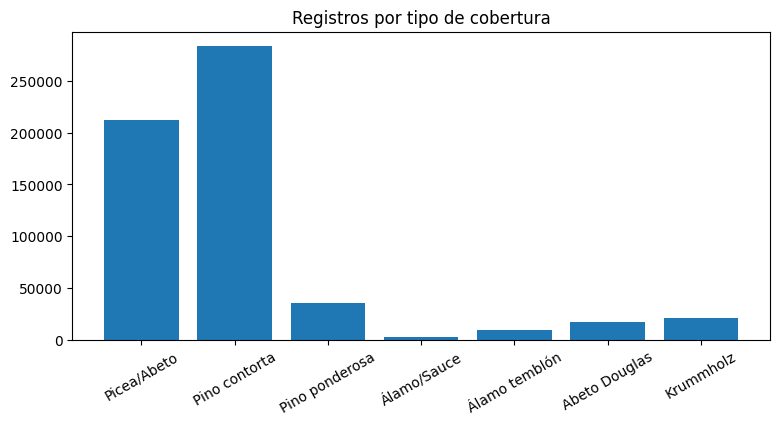

In [9]:
conteo = df['Cover_Type'].value_counts().sort_index()
print(conteo)
print((conteo / len(df) * 100).round(2))

plt.figure(figsize=(9, 4))
plt.bar(conteo.index.map(CLASES), conteo.values)
plt.title('Registros por tipo de cobertura')
plt.xticks(rotation=30)
plt.show()

## Estadística descriptiva

In [10]:
df[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


## Distribución de las variables numéricas
Las variables numéricas no siguen una distribución normal. Las distancias a hidrología, a vías y a puntos de fuego, y también la pendiente, tienen asimetría hacia la derecha: la mayoría de los valores son pequeños y hay una cola larga de valores altos (hasta 1.397 m en hidrología y más de 7.000 m en vías y fuego). Los sombreados de las 9 am y del mediodía son lo contrario: casi todos los valores son altos (medianas de 218 y 226) y la cola va hacia 0. La elevación se concentra entre unos 2.800 y 3.160 m, con una cola hacia las zonas bajas. Aspect es una variable circular (0° y 360° son lo mismo) y hay más registros hacia el norte y el este que hacia el sur y el oeste.

Además, las escalas son muy distintas: la elevación va de 1.859 a 3.858, las distancias llegan a unos 7.000, los sombreados van de 0 a 254 y la pendiente de 0 a 66. Por eso hay que estandarizar las variables antes de usar modelos basados en distancias o en gradientes, como KNN, regresión logística y K-Means. El Random Forest no lo necesita.

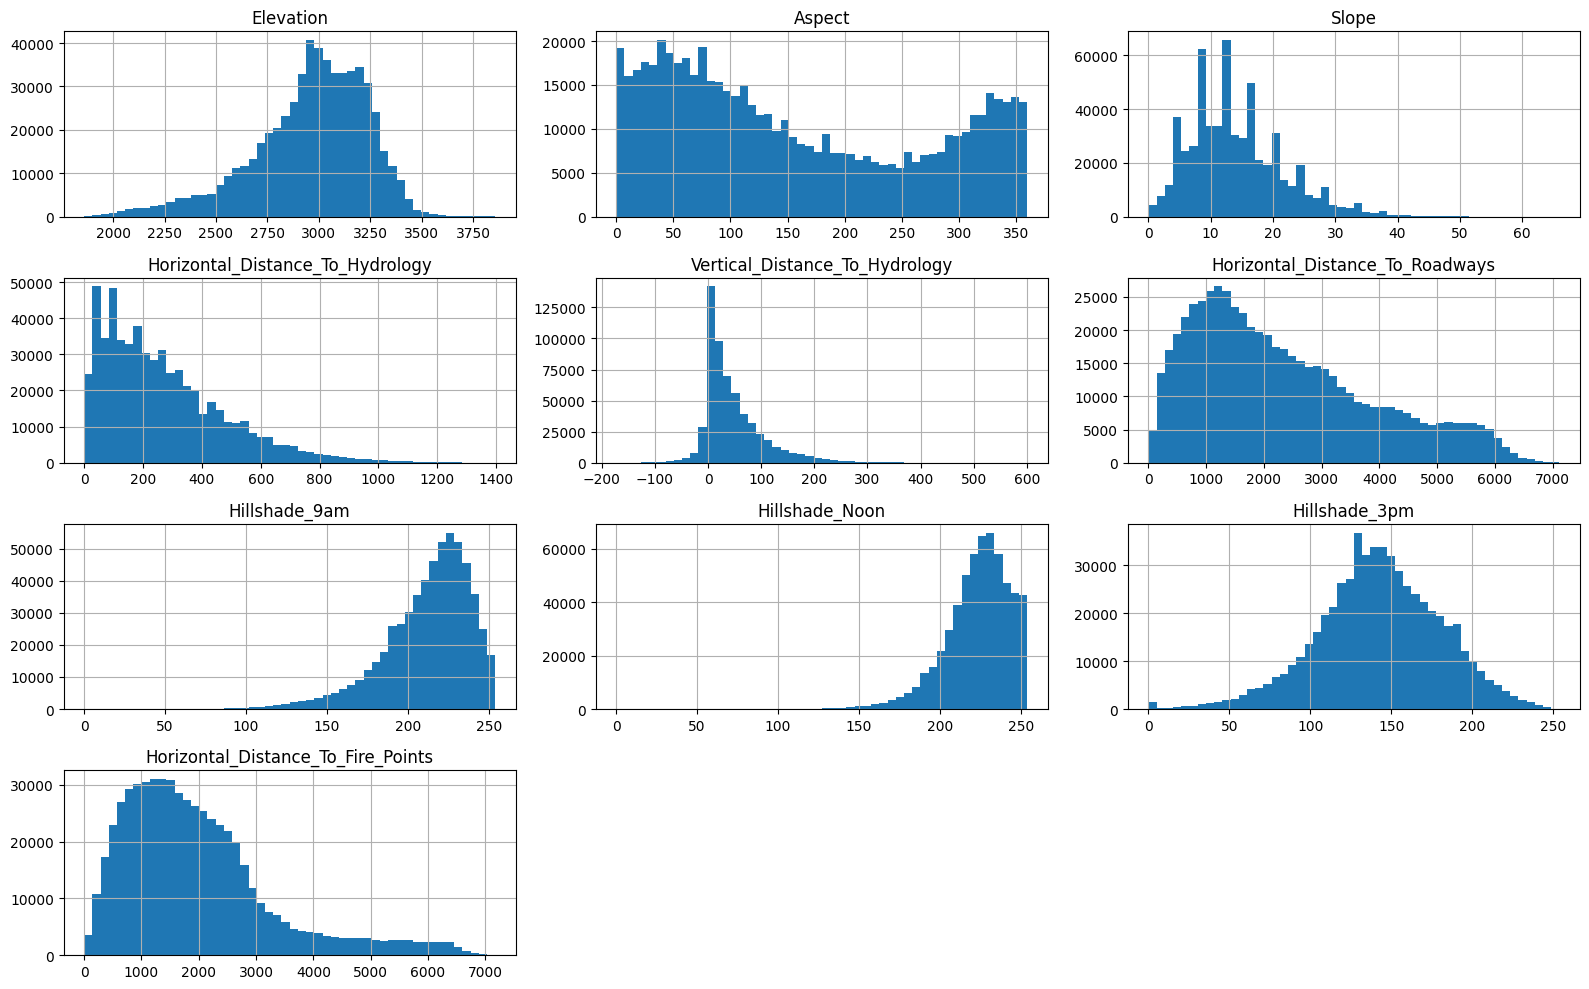

In [11]:
df[NUMERICAS].hist(bins=50, figsize=(16, 10))
plt.tight_layout()
plt.show()

## Valores atípicos
Se cuentan los valores por fuera de 1.5 veces el rango intercuartílico.

Con el criterio de 1,5 veces el rango intercuartílico, las variables con más atípicos son la distancia vertical a hidrología (31.463 valores, 5,42 %) y la distancia a puntos de fuego (31.157, 5,36 %). Les siguen los sombreados de las 9 am (3,00 %) y del mediodía (2,70 %), la elevación (2,68 %), la pendiente (2,64 %) y la distancia horizontal a hidrología (2,51 %). Aspect no tiene ninguno, y la distancia a vías casi no tiene (0,12 %).

No se eliminan porque no son errores: son medidas reales del terreno. Por ejemplo, hay 55.143 registros (9,49 %) con distancia vertical negativa, que corresponden a puntos que están por debajo del nivel del agua más cercana, algo normal en esta zona. Además, estos valores extremos son los que pueden ayudar a distinguir algunas coberturas, y eliminarlos significaría perder información. Los modelos que se usan (sobre todo los de árboles) son poco sensibles a ellos, y en los que sí lo son se estandarizan las variables.

In [12]:
for col in NUMERICAS:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    atipicos = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {atipicos} atípicos ({atipicos / len(df):.2%})")

print("Distancias verticales negativas:", (df['Vertical_Distance_To_Hydrology'] < 0).sum())

Elevation: 15569 atípicos (2.68%)
Aspect: 0 atípicos (0.00%)
Slope: 15316 atípicos (2.64%)
Horizontal_Distance_To_Hydrology: 14557 atípicos (2.51%)
Vertical_Distance_To_Hydrology: 31463 atípicos (5.42%)
Horizontal_Distance_To_Roadways: 669 atípicos (0.12%)
Hillshade_9am: 17433 atípicos (3.00%)
Hillshade_Noon: 15672 atípicos (2.70%)
Hillshade_3pm: 7832 atípicos (1.35%)
Horizontal_Distance_To_Fire_Points: 31157 atípicos (5.36%)
Distancias verticales negativas: 55143


## Variables numéricas según la cobertura
La variable que mejor separa las coberturas es la elevación. Las medianas van de 2.231 m en la clase 4 y 2.404 m en la clase 3 hasta 3.146 m en la clase 1 y 3.363 m en la clase 7, y una medida de cuánto se diferencian los grupos da 0,62 para la elevación contra menos de 0,10 para la distancia a vías, la distancia a puntos de fuego y la pendiente.

Aun así, ninguna variable separa las siete clases por sí sola. Las clases 1 y 2 se solapan bastante en elevación (medianas de 3.146 y 2.935 m), y las clases 3 y 6 son casi iguales (2.404 y 2.428 m). La clase 5 queda en una zona intermedia que también se cruza con la 2. Con las otras variables pasa algo parecido: las clases 3, 4 y 6 están más cerca de las vías (medianas de 850 a 950 m) y en terrenos más empinados (pendiente mediana de 19 a 21) que las clases 1, 2 y 7 (vías a 2.000-2.650 m y pendiente de 12 a 13), pero dentro de cada grupo se parecen mucho entre sí; por ejemplo, las clases 1 y 2 tienen casi la misma distancia a puntos de fuego (1.825 y 1.846 m).

Esto indica que hay que combinar varias variables y que las parejas 1-2 y 3-6 probablemente serán las más difíciles de distinguir para los modelos.

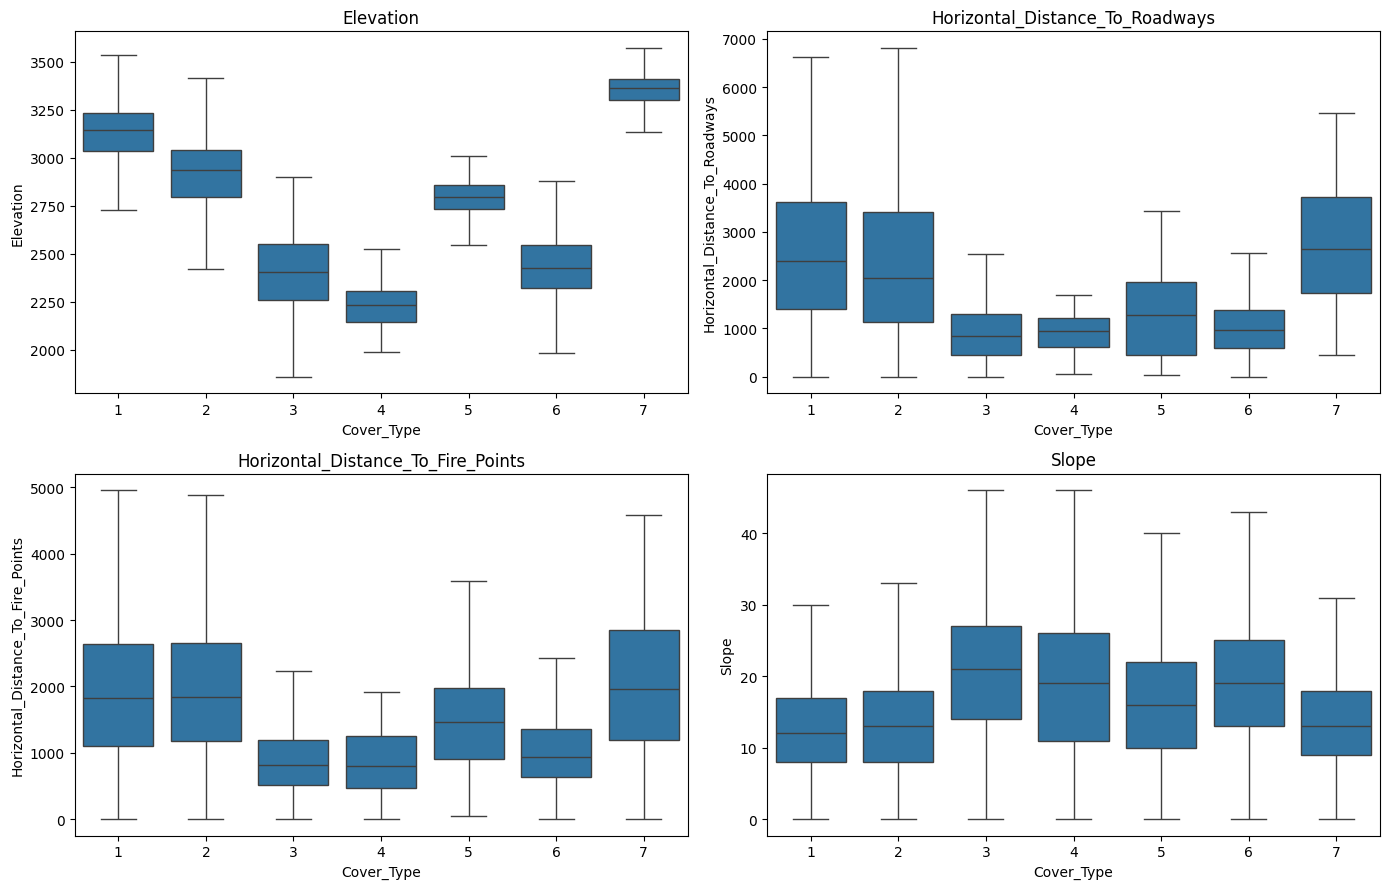

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ['Elevation', 'Horizontal_Distance_To_Roadways',
                               'Horizontal_Distance_To_Fire_Points', 'Slope']):
    sns.boxplot(data=df, x='Cover_Type', y=col, showfliers=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Área silvestre y cobertura
Las áreas 1 y 3 concentran casi el 90 % de los registros (260.796 y 253.364), mientras que las áreas 4 y 2 son pequeñas (36.968 y 29.884). En las áreas 1, 2 y 3 dominan las clases 1 y 2 (por ejemplo, en el área 1 son el 40,5 % y el 56,1 %), y la clase 7 solo aparece en esas tres áreas. El área 4 es muy distinta: está formada sobre todo por la clase 3 (58,0 %) y la clase 6 (26,3 %), con algo de clase 2 (8,2 %) y clase 4 (7,4 %), y no tiene clases 1, 5 ni 7. La clase 4 aparece únicamente en el área 4, y las clases 3 y 6 solo en las áreas 3 y 4. Esto muestra que el área silvestre aporta información útil, porque con solo saber el área ya se descartan varias coberturas.

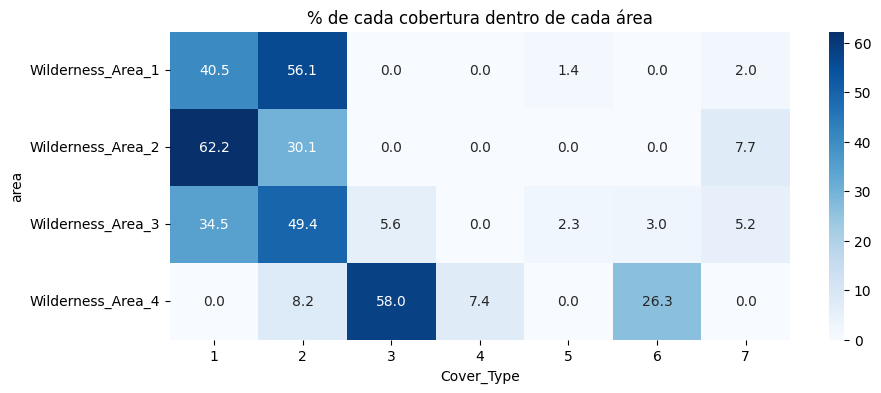

In [14]:
tabla_area = pd.crosstab(df['area'], df['Cover_Type'], normalize='index') * 100
plt.figure(figsize=(10, 4))
sns.heatmap(tabla_area, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de cada cobertura dentro de cada área')
plt.show()

## Tipos de suelo
Los tipos de suelo están muy desiguales: los cuatro más frecuentes (29, 23, 32 y 33) reúnen cerca del 47 % de los registros, y solo el suelo 29 tiene 115.247. En el otro extremo, seis suelos tienen menos del 0,1 % de los registros: el 7 (105), el 8 (179), el 15 (solo 3), el 25 (474), el 36 (119) y el 37 (298). En cuanto a su relación con la cobertura, solo 4 de los 40 suelos tienen el 95 % o más de sus registros en una sola cobertura, y ninguno de los que superan los 5.000 registros llega a ese nivel. En general, cada suelo mezcla varias clases, por lo que sirve como apoyo pero no basta por sí solo para identificar la cobertura. Los suelos casi vacíos aportan muy poca información y podrían generar ruido.

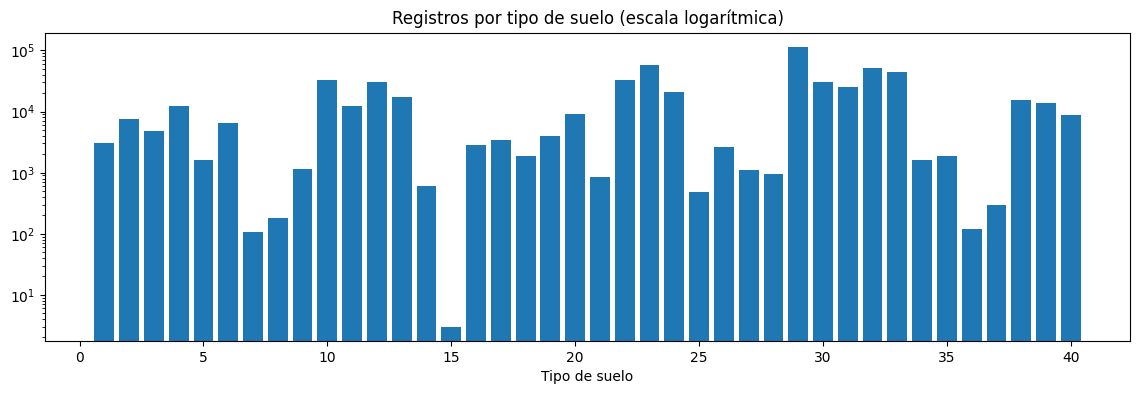

Suelos con menos de 0.1% de los registros:
Soil_Type_7     105
Soil_Type_8     179
Soil_Type_15      3
Soil_Type_25    474
Soil_Type_36    119
Soil_Type_37    298
dtype: int64


In [15]:
conteo_suelo = df[SUELOS].sum()
plt.figure(figsize=(14, 4))
plt.bar(range(1, 41), conteo_suelo.values)
plt.yscale('log')
plt.title('Registros por tipo de suelo (escala logarítmica)')
plt.xlabel('Tipo de suelo')
plt.show()

print("Suelos con menos de 0.1% de los registros:")
print(conteo_suelo[conteo_suelo < len(df) * 0.001])

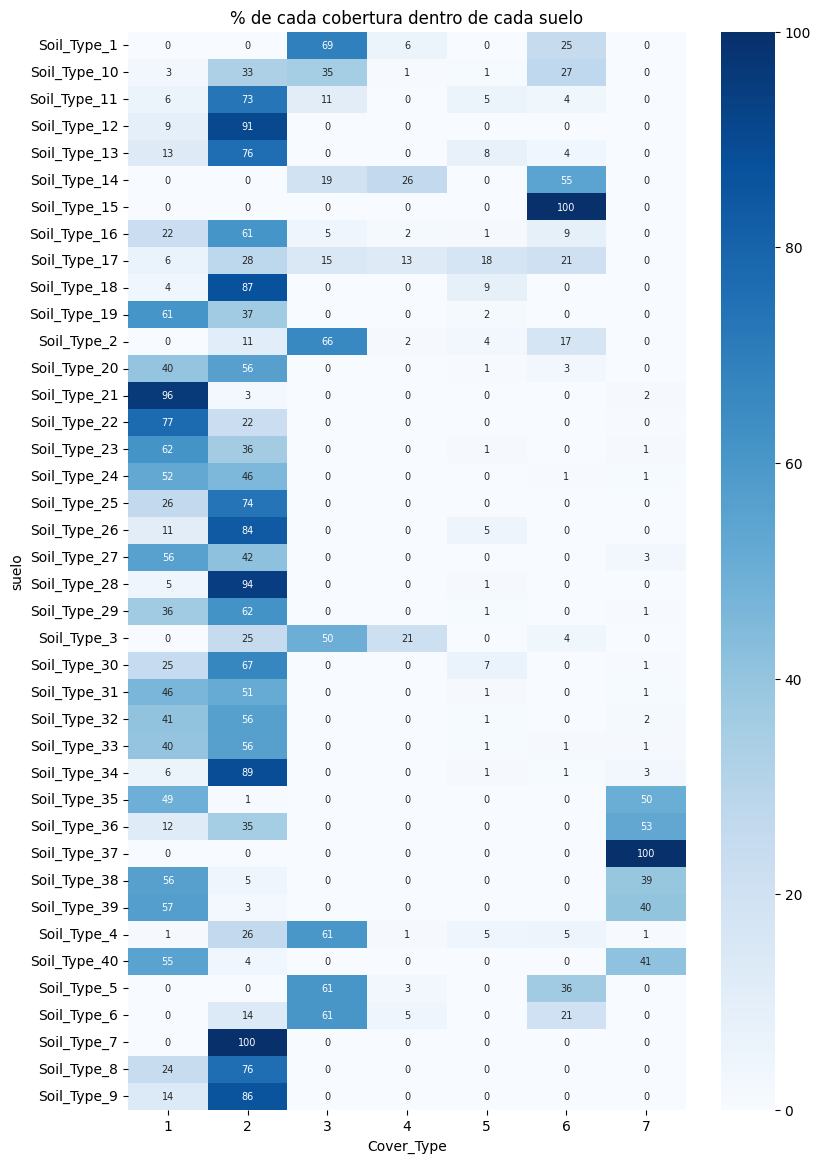

In [16]:
tabla_suelo = pd.crosstab(df['suelo'], df['Cover_Type'], normalize='index') * 100
plt.figure(figsize=(9, 14))
sns.heatmap(tabla_suelo, annot=True, fmt='.0f', cmap='Blues', annot_kws={'size': 7})
plt.title('% de cada cobertura dentro de cada suelo')
plt.show()

## Matriz de correlación
Las correlaciones entre las variables numéricas son moderadas. La más alta es entre el sombreado de las 9 am y el de las 3 pm (-0,78), seguida por Aspect con el sombreado de las 3 pm (0,65), la distancia horizontal con la vertical a hidrología (0,61) y el sombreado del mediodía con el de las 3 pm (0,59). Es lógico que los sombreados dependan de la orientación (Aspect) y de la pendiente, porque se calculan a partir de la luz del sol sobre el terreno. Las distancias a vías y a puntos de fuego casi no se relacionan con las de hidrología (0,07 y 0,05). Solo un par supera 0,7 en valor absoluto y ninguno llega a 0,8, así que no hay variables redundantes que haya que eliminar. Esta matriz mide solo relaciones lineales, y por eso se usan también modelos que captan relaciones no lineales.

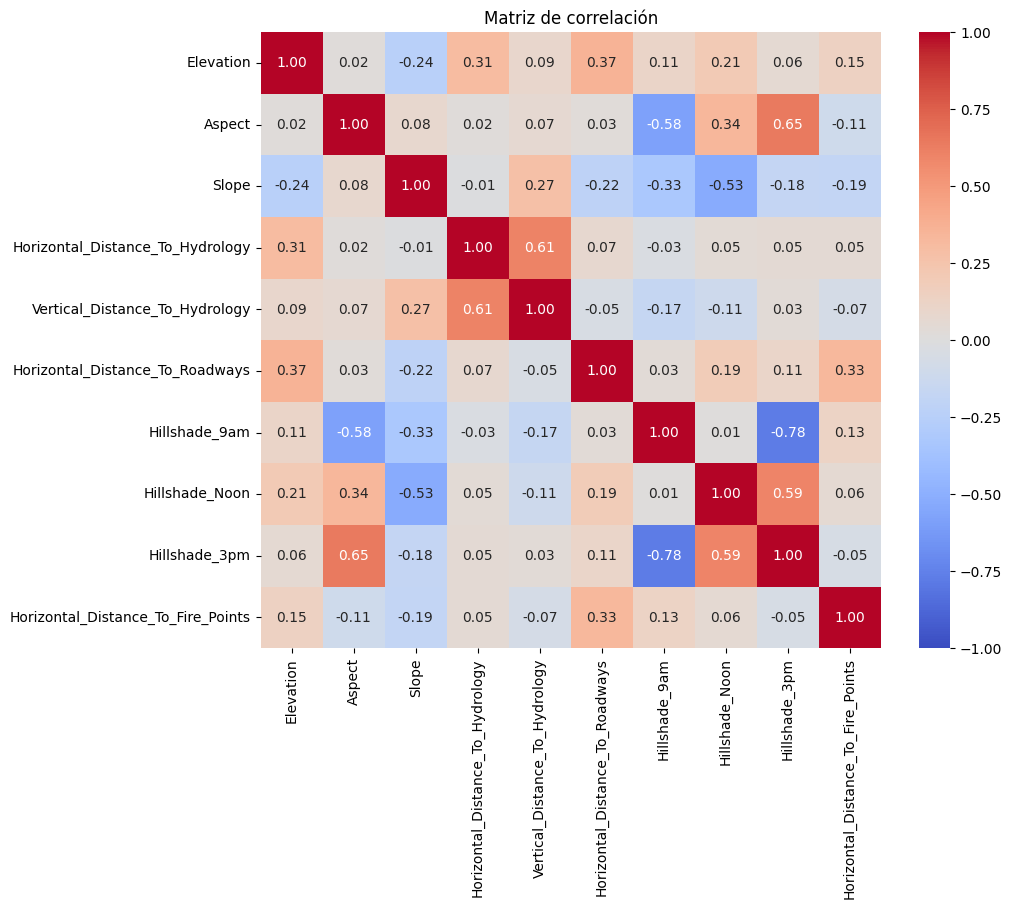

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[NUMERICAS].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

## 3. Preprocesamiento


El dataset al no tener nulos y que las variables categóricas ya están en formato binario, no es necesario imputar, que es llenar vacíos, o codificar, que es pasar categorías o textos a números. Solo es necesario estandarizar las columnas numéricas, haciendo que todas tengan media 0 y desviación 1, evitando que alguna columna domine solo por tener números mas grandes, como las distancias de las carreteras.
Se divide el dataset en dos partes un 80% para el entrenamiento del modelo y un 20% para las pruebas.

Para evitar la fuga de información, el escalado se hace dentro de un Pipeline, así solo aprende la media y la desviación de los datos de entrenamiento y los datos de prueba no influyen en el modelo.

## Partición entrenamiento y prueba
80% entrenamiento y 20% prueba, estratificado por la clase.

In [18]:
from sklearn.model_selection import train_test_split

X = df[VARIABLES]
y = df['Cover_Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)

Entrenamiento: (464809, 54) Prueba: (116203, 54)


## Muestra

El trabajar con las 465 mil filas que trae el dataset puede hacer que modelos como KNN tarden demasiado en ejecutar debido a la gran cantidad de datos, por eso es necesario reducir la cantidad a una muestra de 100 mil registros, para que de está manera se reduzca el tiempo de ejecución manteniendo las proporciones originales.

In [19]:
X_m, _, y_m, _ = train_test_split(X_train, y_train, train_size=100000, stratify=y_train, random_state=42)

proporciones = pd.DataFrame({
    'completo': y.value_counts(normalize=True),
    'muestra': y_m.value_counts(normalize=True),
}).sort_index() * 100
proporciones.round(3)

,completo,muestra
Cover_Type,,
1,36.461,36.460
2,48.760,48.760
3,6.154,6.154
4,0.473,0.473
5,1.634,1.634
6,2.989,2.989
7,3.530,3.530


## Selección de variables

Se hace con un a muestra de 20 mil filas por motivos de eficiencia, ya que hacer la clasificación sobre muchos registros seria un proceso muy pesado, con 20 mil registros es una cantidad suficiente para obtener el ranking de importancia rápidamente, cuando se evalúan las variables, las que mas aportan son la elevación, las áreas silvestres y las distancias. Mientras que las que menos aportan son ciertos tipos de suelo por tener muy pocos registros activos, es decir, que casi todas sus filas están en 0, por su valor binario.

Elevation                             0.455787
Wilderness_Area_4                     0.144948
Horizontal_Distance_To_Roadways       0.094216
Horizontal_Distance_To_Fire_Points    0.068821
Wilderness_Area_1                     0.066963
Soil_Type_10                          0.064780
Slope                                 0.038527
Soil_Type_39                          0.033326
Hillshade_9am                         0.032727
Soil_Type_29                          0.029660
Soil_Type_38                          0.029379
Soil_Type_4                           0.028472
Soil_Type_12                          0.024989
Soil_Type_22                          0.024479
Horizontal_Distance_To_Hydrology      0.024311
Hillshade_3pm                         0.024266
Soil_Type_2                           0.024071
Soil_Type_23                          0.022171
Soil_Type_6                           0.019071
Soil_Type_40                          0.016580
dtype: float64


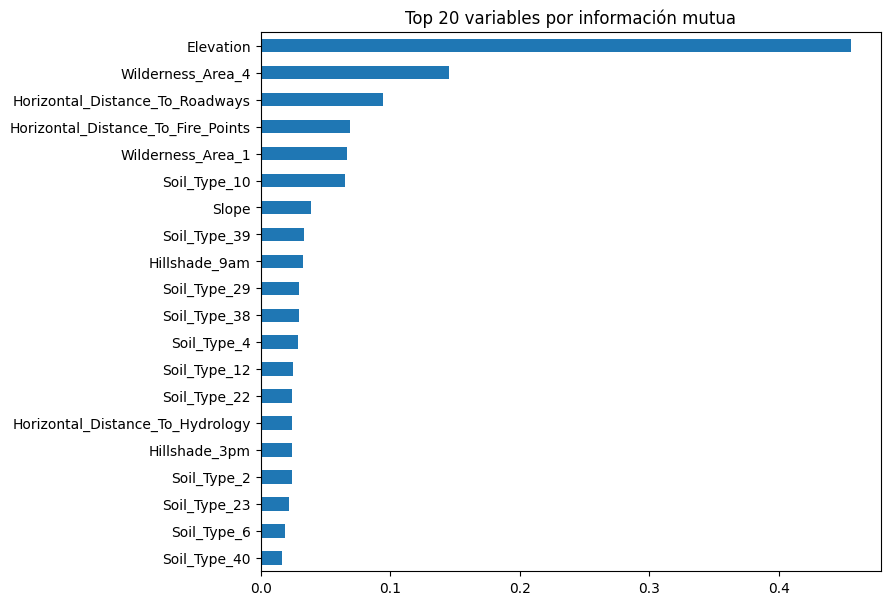

In [20]:
from sklearn.feature_selection import mutual_info_classif

X_mi, _, y_mi, _ = train_test_split(X_m, y_m, train_size=20000, stratify=y_m, random_state=42)
discretas = [col in AREAS + SUELOS for col in VARIABLES]
mi = mutual_info_classif(X_mi, y_mi, discrete_features=discretas, random_state=42)
mi = pd.Series(mi, index=VARIABLES).sort_values(ascending=False)
print(mi.head(20))

top20 = mi.head(20).index.tolist()

mi.head(20).sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Top 20 variables por información mutua')
plt.show()

## Escalado
Solo se escalan las numéricas, las binarias pasan igual.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

escalado = ColumnTransformer([('num', StandardScaler(), NUMERICAS)], remainder='passthrough')